# ARIMA model training and 2026 evaluation

## Academic objective

This notebook demonstrates a classical statistical baseline for daily BTC-USD closing prices. ARIMA is useful here because it makes serial dependence and differencing explicit, is inexpensive to refit on a univariate series, and provides interpretable coefficients and forecast intervals. It assumes that after differencing, the modeled dependence is adequately represented by a linear autoregressive and moving-average process. Crypto returns can change regime, exhibit heavy tails, and respond to external events, so those assumptions are not guaranteed.

For an ARIMA(p,d,q) process, let B be the lag operator and εₜ be a zero-mean innovation. The model is

    φ(B)(1 − B)^d yₜ = c + θ(B) εₜ

where p counts autoregressive lags, d is the differencing order, and q counts lagged innovations. The Augmented Dickey–Fuller test checks a unit-root null; it informs differencing but does not prove stationarity or model adequacy.

**Information boundary:** training targets end December 31, 2023; orders are selected on 2024 validation targets; the selected order is refit through December 31, 2025. 2026 targets are kept for the final evaluation only. No 2026 observation updates parameters or order selection.

## 1. Reproducible environment and source modules

The notebook calls the project's `RollingARIMAForecaster`, feature builder, and shared metrics. Install the project environment with the ARIMA and notebook extras before running. All model fits begin from library defaults and the project's BTC history; no pretrained model is involved.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
import sys
import uuid
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "src" / "btc_forecasting").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the BTC forecasting project.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from btc_forecasting.data import load_ohlcv_csv
from btc_forecasting.features import make_features
from btc_forecasting.metrics import evaluate_predictions

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

CONFIG_PATH = PROJECT_ROOT / "configs" / "default.yaml"
with CONFIG_PATH.open(encoding="utf-8") as stream:
    PROJECT_CONFIG = yaml.safe_load(stream)

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def package_version(name: str) -> str:
    try:
        return version(name)
    except PackageNotFoundError:
        return "not-installed"

def make_run_id(model_name: str) -> str:
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    return f"{stamp}_notebook_{model_name}_{uuid.uuid4().hex[:8]}"

PLOT_OUTPUTS = {}
EXTRA_TABLES = {}

def capture_plot(name, figure):
    import io
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=160, bbox_inches="tight")
    PLOT_OUTPUTS[name] = buffer.getvalue()

def save_run(model_name, run_id, predictions, metrics, validation_scores,
             configuration, model_metadata, save_model):
    """Create a new run directory and refuse every path collision."""
    run_dir = PROJECT_ROOT / "artifacts" / "runs" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    model_dir = run_dir / "models"
    model_dir.mkdir()
    model_relative_path = save_model(model_dir)
    for name, image_bytes in PLOT_OUTPUTS.items():
        (run_dir / name).write_bytes(image_bytes)
    for name, table in EXTRA_TABLES.items():
        table.to_csv(run_dir / name, index=True)
    predictions.to_csv(run_dir / "predictions.csv", index=False)
    metrics.to_csv(run_dir / "metrics.csv", index_label="model")
    validation_scores.to_csv(run_dir / "validation_scores.csv", index=False)
    (run_dir / "configuration.json").write_text(
        json.dumps(configuration, indent=2, sort_keys=True, default=str) + "\n",
        encoding="utf-8",
    )
    metadata = {
        "run_id": run_id,
        "notebook_experiment": True,
        "notebook_model": model_name,
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_sha256": RAW_SHA256,
        "raw_data_sha256": RAW_SHA256,
        "features_sha256": FEATURES_SHA256,
        "raw_data_file": str(RAW_PATH),
        "target_column": TARGET_COLUMN,
        "horizon_days": 1,
        "prediction_index": "decision date; target date is the following calendar date",
        "split_ranges_by_target_date": SPLIT_CONFIG,
        "rows": {"train": len(TRAIN), "validation": len(VALIDATION),
                 "final_fit": len(DEVELOPMENT), "final_evaluation": len(TEST)},
        "feature_columns": FEATURE_COLUMNS,
        "model": model_metadata,
        "model_artifacts": {model_name: model_relative_path},
        "software_versions": {
            "python": platform.python_version(),
            "numpy": package_version("numpy"),
            "pandas": package_version("pandas"),
            "statsmodels": package_version("statsmodels"),
            "pmdarima": package_version("pmdarima"),
            "scikit-learn": package_version("scikit-learn"),
            "xgboost": package_version("xgboost"),
            "torch": package_version("torch"),
            "matplotlib": package_version("matplotlib"),
        },
    }
    (run_dir / "metadata.json").write_text(
        json.dumps(metadata, indent=2, sort_keys=True, default=str) + "\n",
        encoding="utf-8",
    )
    return run_dir

## 2. Data provenance and temporal partitions

The notebook uses the newest immutable OHLCV snapshot already present in `data/raw/`. It does not download or replace data. Features are rebuilt with the project's causal feature function; no feature row uses a later candle. The next-close target is kept separate from the model inputs.

Training and validation are assigned by **target date**. A row dated *t* uses information through the close on *t* and predicts *t+1*. Thus the train/validation boundary does not accidentally put a January 1 target into training merely because its decision row is dated December 31.

In [2]:
import hashlib
from btc_forecasting.features import TARGET_COLUMNS

RAW_DIRECTORY = PROJECT_ROOT / "data" / "raw"
raw_candidates = sorted(RAW_DIRECTORY.glob("*.csv"))
if not raw_candidates:
    raise FileNotFoundError("No raw OHLCV snapshots found under data/raw/.")
RAW_PATH = raw_candidates[-1]
raw = load_ohlcv_csv(RAW_PATH)
RAW_SHA256 = sha256_file(RAW_PATH)
TARGET_COLUMN = PROJECT_CONFIG["target"]["column"]
if TARGET_COLUMN != "Target_Next_Close":
    raise ValueError("These demonstrations require the project's one-day next-close target.")

frame = make_features(raw, drop_incomplete=False)
FEATURE_COLUMNS = [c for c in frame.columns if c not in TARGET_COLUMNS and not str(c).startswith("Target_")]
frame = frame.dropna(subset=FEATURE_COLUMNS).copy()
frame["Target_Date"] = frame.index + pd.Timedelta(days=1)
frame["Target_Next_Close"] = pd.to_numeric(frame["Target_Next_Close"], errors="coerce")
frame = frame.replace([np.inf, -np.inf], np.nan)
FEATURES_SHA256 = hashlib.sha256(
    frame.reset_index().to_csv(index=False, date_format="%Y-%m-%d").encode("utf-8")
).hexdigest()

SPLIT_CONFIG = {
    "training_target_dates": ["2018-01-01", "2023-12-31"],
    "validation_target_dates": ["2024-01-01", "2024-12-31"],
    "final_fit_target_dates": ["2018-01-01", "2025-12-31"],
    "final_evaluation_target_dates": ["2026-01-01", str(raw.index[-1].date())],
    "evaluation_strategy": "rolling one-day-ahead; weights and hyperparameters frozen throughout 2026",
}
target_dates = frame["Target_Date"]
has_target = frame[TARGET_COLUMN].notna()
TRAIN = frame.loc[has_target & (target_dates <= "2023-12-31")].copy()
VALIDATION = frame.loc[
    has_target & target_dates.between("2024-01-01", "2024-12-31", inclusive="both")
].copy()
DEVELOPMENT = frame.loc[has_target & (target_dates <= "2025-12-31")].copy()
TEST = frame.loc[has_target & (target_dates >= "2026-01-01")].copy()

assert not TRAIN.empty and not VALIDATION.empty and not DEVELOPMENT.empty and not TEST.empty
assert TRAIN["Target_Date"].max() <= pd.Timestamp("2023-12-31")
assert VALIDATION["Target_Date"].min() >= pd.Timestamp("2024-01-01")
assert VALIDATION["Target_Date"].max() <= pd.Timestamp("2024-12-31")
assert DEVELOPMENT["Target_Date"].max() <= pd.Timestamp("2025-12-31")
assert TEST["Target_Date"].min() >= pd.Timestamp("2026-01-01")
assert TEST["Target_Date"].max() <= raw.index[-1]

print(f"Raw source: {RAW_PATH}")
print(f"Raw SHA-256: {RAW_SHA256}")
print(f"Feature SHA-256: {FEATURES_SHA256}")
print(f"Latest observed BTC close date: {raw.index[-1].date()}")
print(f"Last target date with an actual next close: {TEST['Target_Date'].max().date()}")
display(pd.DataFrame([
    {"partition": "Train", "first_target_date": TRAIN.Target_Date.min().date(),
     "last_target_date": TRAIN.Target_Date.max().date(), "rows": len(TRAIN)},
    {"partition": "Validation", "first_target_date": VALIDATION.Target_Date.min().date(),
     "last_target_date": VALIDATION.Target_Date.max().date(), "rows": len(VALIDATION)},
    {"partition": "Final model fit", "first_target_date": DEVELOPMENT.Target_Date.min().date(),
     "last_target_date": DEVELOPMENT.Target_Date.max().date(), "rows": len(DEVELOPMENT)},
    {"partition": "Unseen 2026 evaluation", "first_target_date": TEST.Target_Date.min().date(),
     "last_target_date": TEST.Target_Date.max().date(), "rows": len(TEST)},
]))

feature_columns = FEATURE_COLUMNS
train = TRAIN
validation = VALIDATION
development = DEVELOPMENT
test = TEST

Raw source: C:\Users\Manya Chaubey\Downloads\Crypto\data\raw\BTC-USD_20180101_20261114_20261115T172122Z.csv
Raw SHA-256: deb1ce1e9955cfb8290783516159e9519c7337f3fb95e320401332d622a18e87
Feature SHA-256: 1210f3dd28aceb38e2d22859c4fd2fd7de19b7850f7c2bc4002f6b7a7d1f0533
Latest observed BTC close date: 2026-11-14
Last target date with an actual next close: 2026-11-14


,partition,first_target_date,last_target_date,rows
0,Train,2018-07-20,2023-12-31,1991
1,Validation,2024-01-01,2024-12-31,366
2,Final model fit,2018-07-20,2025-12-31,2722
3,Unseen 2026 evaluation,2026-01-01,2026-11-14,318


In [3]:
from btc_forecasting.models.arima import RollingARIMAForecaster
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from btc_forecasting.metrics import evaluate_predictions
from scripts.run_experiment import _rolling_arima_predictions

training_close = pd.to_numeric(
    frame.loc[frame.index <= pd.Timestamp("2023-12-31"), "Close"], errors="raise"
)
if training_close.index[-1] != pd.Timestamp("2023-12-31"):
    raise ValueError("Training close history must end on 2023-12-31.")

def adf_summary(values, label):
    result = adfuller(values.dropna(), regression="c", autolag="AIC")
    return {"series": label, "ADF statistic": result[0], "p-value": result[1],
            "used lags": result[2], "observations": result[3]}

stationarity = pd.DataFrame([
    adf_summary(training_close, "Training close (level)"),
    adf_summary(training_close.diff(), "Training close (first difference)"),
])
display(stationarity.round(5))

C:\Users\MANYAC~1\AppData\Local\Temp\ipykernel_31804\2063126529.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values.dropna(), regression="c", autolag="AIC")
C:\Users\MANYAC~1\AppData\Local\Temp\ipykernel_31804\2063126529.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values.dropna(), regression="c", autolag="AIC")


,series,ADF statistic,p-value,used lags,observations
0,Training close (level),-1.40669,0.57906,24,1967
1,Training close (first difference),-8.73150,0.00000,23,1967


## 3. Validation-based order selection

Candidate orders are declared before examining 2026 and fitted only on the 2018–2023 close history. Each candidate produces sequential one-day forecasts across 2024: after each forecast, the actual close for that already elapsed date is appended without refitting parameters. The 2024 next-close RMSE selects the order. AIC is also reported as a training-fit diagnostic, not as a substitute for the untouched 2026 evaluation.

In [4]:
from itertools import product

candidate_orders = [(0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1), (2, 1, 1)]
validation_rows = []
validation_forecasts = {}
for order in candidate_orders:
    candidate_result = ARIMA(training_close.asfreq("D"), order=order).fit()
    forecast = _rolling_arima_predictions(
        training_close, VALIDATION, order=order, target_column=TARGET_COLUMN
    )
    validation_forecasts[order] = forecast
    scores = evaluate_predictions(
        VALIDATION[TARGET_COLUMN], forecast, VALIDATION["Close"]
    )
    validation_rows.append({
        "order": str(order), "p": order[0], "d": order[1], "q": order[2],
        "training_AIC": float(candidate_result.aic), **scores,
    })
validation_scores = pd.DataFrame(validation_rows).sort_values("rmse").reset_index(drop=True)
best_order = tuple(int(v) for v in validation_scores.loc[0, ["p", "d", "q"]])
display(validation_scores.round(4))
print(f"Selected order by 2024 validation RMSE: {best_order}")

C:\Users\Manya Chaubey\Documents\Codex\2026-10-31\he\work\btc-forecasting-312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Manya Chaubey\Documents\Codex\2026-10-31\he\work\btc-forecasting-312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


C:\Users\Manya Chaubey\Documents\Codex\2026-10-31\he\work\btc-forecasting-312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Manya Chaubey\Documents\Codex\2026-10-31\he\work\btc-forecasting-312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,order,p,d,q,training_AIC,mae,rmse,directional_accuracy
0,"(2, 1, 1)",2,1,1,33131.3222,1331.0738,1859.5572,0.5000
1,"(1, 1, 1)",1,1,1,33131.8310,1331.1510,1859.6357,0.5273
2,"(1, 1, 0)",1,1,0,33129.9402,1331.5305,1859.8899,0.5246
3,"(0, 1, 1)",0,1,1,33129.9986,1331.7011,1859.9790,0.5301
4,"(0, 1, 0)",0,1,0,33130.0128,1334.5485,1861.6612,0.0000


Selected order by 2024 validation RMSE: (2, 1, 1)


## 4. Final refit through December 31, 2025

After selecting the order, fit its parameters again using all historical closes through 2025-12-31. The first 2026 decision is made after the December 31 close. Then forecasts proceed chronologically: predict the next close first, and only afterward append that date's actual close to the ARIMA state. Parameter estimates and the chosen order remain fixed for all of 2026.

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 2922
Model:                 ARIMA(2, 1, 1)   Log Likelihood              -25089.420
Date:                Sun, 15 Nov 2026   AIC                          50186.840
Time:                        23:23:58   BIC                          50210.758
Sample:                    01-01-2018   HQIC                         50195.455
                         - 12-31-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0206      9.144     -0.002      0.998     -17.942      17.901
ar.L2          0.0023      0.378      0.006      0.995      -0.738       0.743
ma.L1         -0.0206      9.145     -0.002      0.9

C:\Users\Manya Chaubey\Documents\Codex\2026-10-31\he\work\btc-forecasting-312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Manya Chaubey\Documents\Codex\2026-10-31\he\work\btc-forecasting-312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,estimate
ar.L1,-2.056929e-02
ar.L2,2.258237e-03
ma.L1,-2.063352e-02
sigma2,1.690948e+06


C:\Users\Manya Chaubey\Documents\Codex\2026-10-31\he\work\btc-forecasting-312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\Manya Chaubey\Documents\Codex\2026-10-31\he\work\btc-forecasting-312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


2026 final evaluation, USD close-price errors:


,mae,rmse,directional_accuracy
ARIMA,1181.2662,1728.3102,0.4874


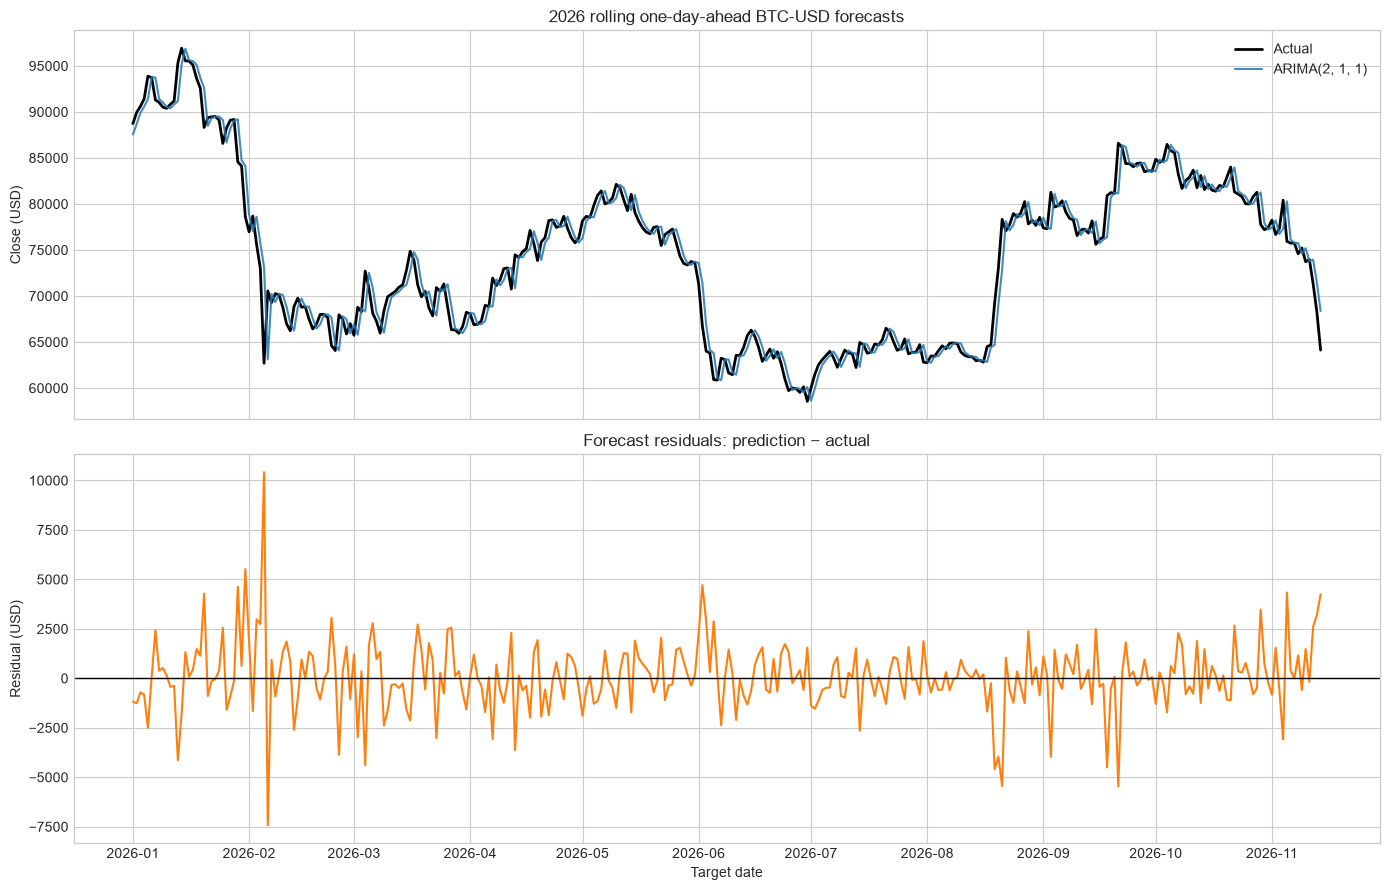

In [5]:
from btc_forecasting.metrics import evaluate_predictions

development_close = pd.to_numeric(
    raw.loc[raw.index <= pd.Timestamp("2025-12-31"), "Close"], errors="raise"
)
assert development_close.index[-1] == pd.Timestamp("2025-12-31")
final_arima_result = ARIMA(development_close.asfreq("D"), order=best_order).fit()
print(final_arima_result.summary())
print("\nFitted coefficients:")
display(final_arima_result.params.rename("estimate").to_frame())

arima_forecaster = RollingARIMAForecaster(best_order).fit(development_close)
arima_predictions = []
for decision_date, row in TEST.iterrows():
    # No current target is read until after this forecast has been generated.
    prediction = arima_forecaster.forecast_next()
    arima_predictions.append(prediction)
    arima_forecaster.observe(row["Target_Date"], float(row[TARGET_COLUMN]))
arima_prediction = pd.Series(arima_predictions, index=TEST.index, name="prediction")
arima_metrics = evaluate_predictions(
    TEST[TARGET_COLUMN], arima_prediction, TEST["Close"]
)
print("2026 final evaluation, USD close-price errors:")
display(pd.DataFrame([arima_metrics], index=["ARIMA"]).round(4))

predictions = pd.DataFrame({
    "decision_date": TEST.index,
    "Target_Date": TEST["Target_Date"].to_numpy(),
    "previous_close_usd": TEST["Close"].to_numpy(),
    "actual_next_close_usd": TEST[TARGET_COLUMN].to_numpy(),
    "prediction_usd": arima_prediction.to_numpy(),
})
residuals = predictions["prediction_usd"] - predictions["actual_next_close_usd"]
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(predictions["Target_Date"], predictions["actual_next_close_usd"],
             label="Actual", color="black", linewidth=2)
axes[0].plot(predictions["Target_Date"], predictions["prediction_usd"],
             label=f"ARIMA{best_order}", alpha=0.85)
axes[0].set_title("2026 rolling one-day-ahead BTC-USD forecasts")
axes[0].set_ylabel("Close (USD)")
axes[0].legend()
axes[1].plot(predictions["Target_Date"], residuals, color="tab:orange")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Forecast residuals: prediction − actual")
axes[1].set_ylabel("Residual (USD)")
axes[1].set_xlabel("Target date")
fig.tight_layout()
capture_plot("2026_forecast_and_residuals.png", fig)
display(fig)
plt.close(fig)

## 5. Residual diagnostics and saved fitted model

Residual diagnostics can reveal remaining autocorrelation, skew, or extreme errors. Passing these checks does not establish that the market process is stable; crypto prices can change regime after the evaluation period.

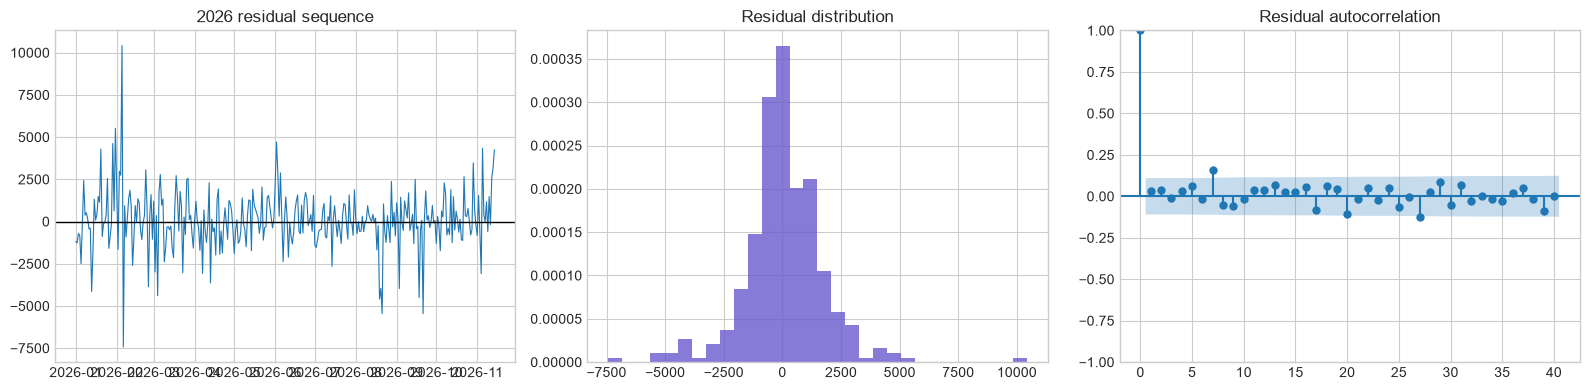

In [6]:
from statsmodels.graphics.tsaplots import plot_acf

residual_series = pd.Series(residuals.to_numpy(), index=pd.DatetimeIndex(predictions["Target_Date"]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(residual_series.index, residual_series, linewidth=0.8)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("2026 residual sequence")
axes[1].hist(residual_series, bins=30, density=True, color="slateblue", alpha=0.8)
axes[1].set_title("Residual distribution")
plot_acf(residual_series, lags=min(40, len(residual_series) // 2 - 1), ax=axes[2])
axes[2].set_title("Residual autocorrelation")
fig.tight_layout()
capture_plot("2026_residual_diagnostics.png", fig)
display(fig)
plt.close(fig)

EXTRA_TABLES["stationarity_tests.csv"] = stationarity.set_index("series")
EXTRA_TABLES["fitted_coefficients.csv"] = final_arima_result.params.rename("estimate").to_frame()
RUN_ID = make_run_id("arima")
ARIMA_CONFIG = {
    "candidate_orders": [list(order) for order in candidate_orders],
    "selection_metric": "2024 validation RMSE",
    "selected_order": list(best_order),
    "training_close_end": "2023-12-31",
    "final_fit_close_end": "2025-12-31",
    "final_evaluation": "2026 rolling one-day-ahead; no refitting or tuning",
}
arima_validation_scores = validation_scores.copy()
arima_metadata = {
    "arima": {
        "order": list(best_order),
        "selection_metric": "2024 validation RMSE",
        "selected_validation_rmse_usd": float(validation_scores.loc[0, "rmse"]),
        "final_fit_close_start": str(development_close.index[0].date()),
        "final_fit_close_end": str(development_close.index[-1].date()),
        "parameters": {str(k): float(v) for k, v in final_arima_result.params.items()},
        "refit_during_2026": False,
    }
}

## 6. Experiment record and artifact

Every run uses a fresh timestamp-and-random-suffix directory. The call refuses to reuse an existing directory. It saves the data hashes, exact split, validation scores, 2026 predictions, metrics, software versions, and fitted ARIMA result.

In [7]:
def save_arima_artifact(model_dir):
    final_arima_result.save(model_dir / "arima_results.pkl")
    return "models/arima_results.pkl"

ARIMA_METRICS = pd.DataFrame([arima_metrics], index=["arima"])
RUN_DIR = save_run(
    "arima", RUN_ID, predictions, ARIMA_METRICS, arima_validation_scores,
    ARIMA_CONFIG, arima_metadata, save_arima_artifact,
)
print(f"Saved unique ARIMA experiment: {RUN_DIR}")
print(f"Model artifact: {RUN_DIR / 'models' / 'arima_results.pkl'}")

Saved unique ARIMA experiment: C:\Users\Manya Chaubey\Downloads\Crypto\artifacts\runs\20261115T175407643905Z_notebook_arima_b43f29b3
Model artifact: C:\Users\Manya Chaubey\Downloads\Crypto\artifacts\runs\20261115T175407643905Z_notebook_arima_b43f29b3\models\arima_results.pkl


## Rolling one-day-ahead versus a fixed 365-day forecast

**Rolling one-day-ahead (used here):** at each decision date, predict only the next close using information then available. Once that date has passed and its close is observed, it may enter later causal features or update ARIMA's state. The learned XGBoost/LSTM parameters and selected hyperparameters remain fixed throughout 2026; ARIMA parameters remain fixed while its state receives already-observed closes. This estimates a repeated operational one-day forecast.

**Fixed-origin 365-day forecast:** at a single origin such as December 31, 2025, produce all forecasts through 2026 without observing any 2026 close between steps. This measures a long-horizon path and requires recursive features or a model that directly predicts all horizons. The existing XGBoost/LSTM one-step feature set cannot produce that path honestly because future OHLCV indicators are unknown. These notebooks therefore do not label rolling forecasts as a 365-day fixed-origin forecast.

The 2026 evaluation ends at the last date with an actual next close in the available raw dataset. Scores describe only that observed interval and should not be generalized to the full calendar year if later dates are unavailable.

## 8. Rolling evaluation and three-model comparison

The comparison cell below reads only completed notebook experiment folders with the same raw-data hash and the same target-date evaluation window. Run all three training notebooks first, then execute this cell in any notebook to refresh the shared comparison. It recomputes metrics from the saved per-date forecasts, verifies that actuals and target dates match, and saves a comparison table and plot in this notebook's unique experiment folder.

,mae,rmse,directional_accuracy
model,,,
arima,1181.2662,1728.3102,0.4874
xgboost,1892.7047,2454.6569,0.4811
lstm,1208.5267,1752.0206,0.4748


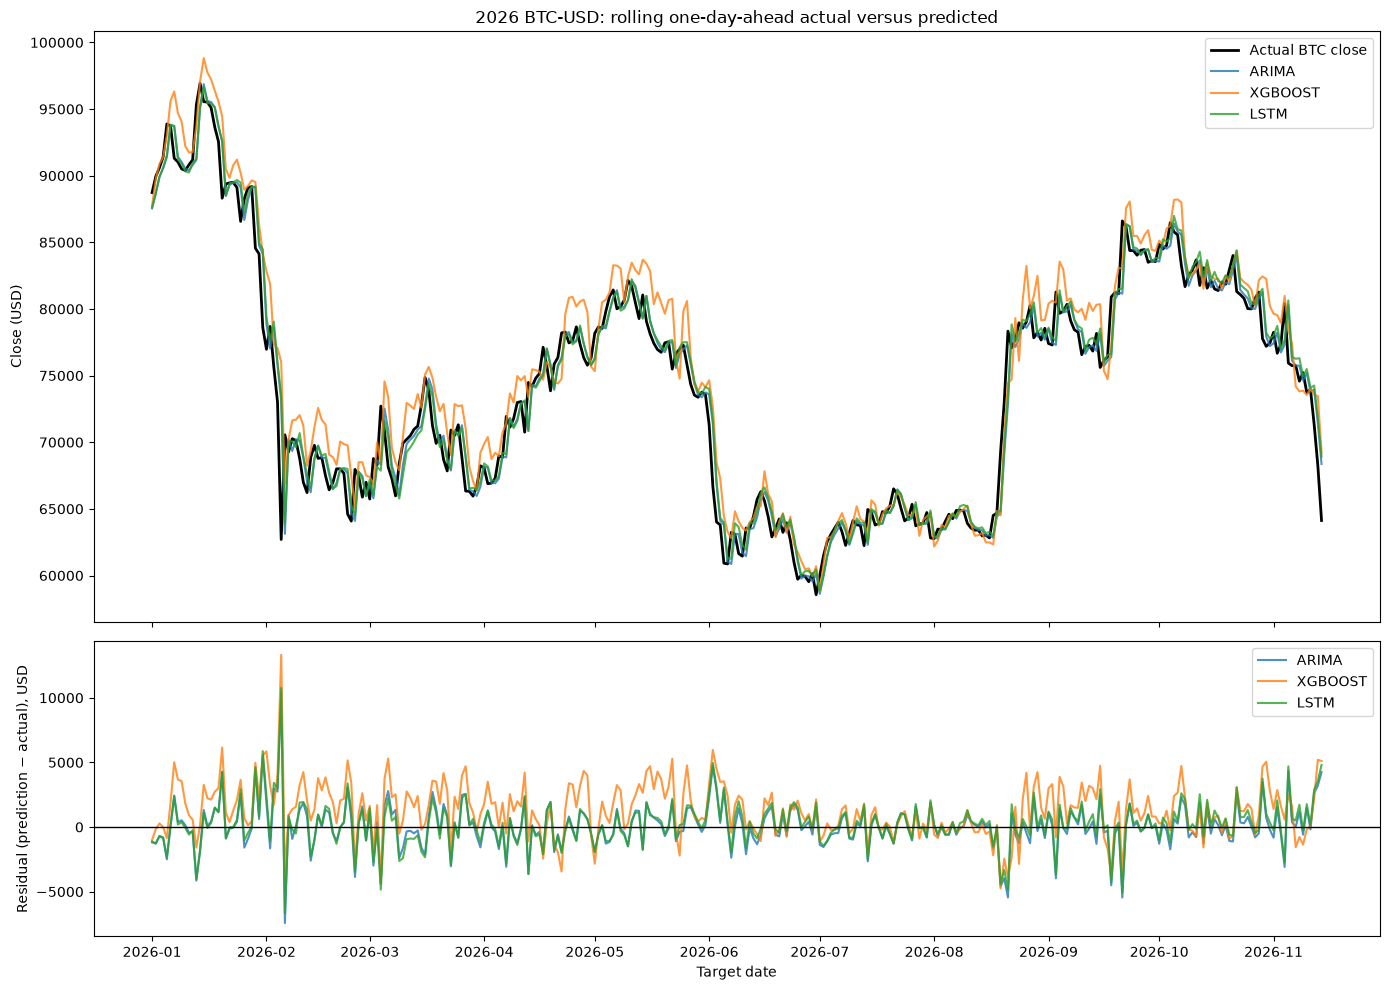

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from btc_forecasting.evaluation import compare_predictions

run_root = PROJECT_ROOT / "artifacts" / "runs"
matching_runs = {"arima": [], "xgboost": [], "lstm": []}
for candidate in run_root.iterdir() if run_root.exists() else []:
    if not candidate.is_dir():
        continue
    try:
        meta = json.loads((candidate / "metadata.json").read_text(encoding="utf-8"))
        model_name = meta.get("notebook_model")
        if (meta.get("notebook_experiment") and model_name in matching_runs
                and meta.get("raw_data_sha256") == RAW_SHA256
                and meta.get("split_ranges_by_target_date", {}).get("final_evaluation_target_dates") == SPLIT_CONFIG["final_evaluation_target_dates"]):
            matching_runs[model_name].append((candidate, meta))
    except (OSError, json.JSONDecodeError):
        continue

missing_models = [name for name, choices in matching_runs.items() if not choices]
if missing_models:
    print("Run the remaining model notebook(s), then re-execute this comparison cell: "
          + ", ".join(missing_models))
else:
    selected_runs = {
        name: sorted(choices, key=lambda item: item[0].name)[-1]
        for name, choices in matching_runs.items()
    }
    prediction_tables = {}
    for name, (folder, meta) in selected_runs.items():
        table = pd.read_csv(folder / "predictions.csv")
        table["Target_Date"] = pd.to_datetime(table["Target_Date"])
        table = table.set_index("Target_Date").sort_index()
        prediction_tables[name] = table
    common_dates = prediction_tables["arima"].index
    for table in prediction_tables.values():
        if not table.index.equals(common_dates):
            raise ValueError("The model runs do not cover exactly the same 2026 target dates.")
        if not np.allclose(table["actual_next_close_usd"], prediction_tables["arima"]["actual_next_close_usd"]):
            raise ValueError("The saved model runs disagree on actual close values.")
    actual = prediction_tables["arima"]["actual_next_close_usd"]
    previous = prediction_tables["arima"]["previous_close_usd"]
    forecasts = {
        name: table["prediction_usd"].rename(name)
        for name, table in prediction_tables.items()
    }
    comparison = compare_predictions(actual, previous, forecasts)
    display(comparison.round(4))
    comparison.to_csv(RUN_DIR / "three_model_comparison_2026.csv", index_label="model")

    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(actual.index, actual, label="Actual BTC close", color="black", linewidth=2)
    for name, forecast in forecasts.items():
        axes[0].plot(forecast.index, forecast, label=name.upper(), alpha=0.8)
        axes[1].plot(forecast.index, forecast - actual, label=name.upper(), alpha=0.8)
    axes[0].set_title("2026 BTC-USD: rolling one-day-ahead actual versus predicted")
    axes[0].set_ylabel("Close (USD)")
    axes[0].legend()
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_ylabel("Residual (prediction − actual), USD")
    axes[1].set_xlabel("Target date")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / "three_model_comparison_2026.png", dpi=160)
    display(fig)
    plt.close(fig)